# Aplicação 2 — Preço de automóveis usados

O objetivo é prever `price` para veículos usados da Mercedes. Serão comparados Regressão Linear Múltipla, Árvore de Regressão, Random Forest e Gradient Boosting em uma divisão 50/50 entre treinamento e teste.

A avaliação utiliza o RMSE de teste e gráficos de valores observados versus previstos. Quanto menor o RMSE, melhor o desempenho preditivo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor

SEMENTE = 42
PROPORCAO_TESTE = 0.5

## 1. Leitura e inspeção

A inspeção verifica dimensões, tipos, valores ausentes e duplicatas. As duplicatas exatas são removidas antes da divisão para impedir que o mesmo veículo apareça nos dois conjuntos. `trim` é tratado como categoria, mesmo quando contém valores semelhantes a números.

In [2]:
automoveis_bruto = pd.read_csv(Path("data") / "used_cars.csv")

print("Dimensões originais:", automoveis_bruto.shape)
print("Valores ausentes:", automoveis_bruto.isna().sum().sum())
print("Duplicatas exatas:", automoveis_bruto.duplicated().sum())
print(automoveis_bruto.dtypes)

automoveis = automoveis_bruto.drop_duplicates().reset_index(drop=True)
print("Dimensões após remover duplicatas:", automoveis.shape)
print(automoveis["price"].describe())

Dimensões originais: (20063, 10)
Valores ausentes: 0
Duplicatas exatas: 15
price           float64
trim                str
isOneOwner          str
mileage         float64
year              int64
color               str
fuel                str
soundSystem         str
wheelType           str
displacement    float64
dtype: object
Dimensões após remover duplicatas: (20048, 10)
count    20048.000000
mean        30.765985
std         18.284716
min          0.599000
25%         13.500000
50%         29.493000
75%         43.995000
max         79.999000
Name: price, dtype: float64


## 2. Divisão e pré-processamento

A resposta `price` é separada das nove variáveis explicativas. A semente fixa o sorteio 50/50. As categorias são transformadas em colunas indicadoras; a primeira categoria de cada variável é usada como referência. As variáveis numéricas permanecem em sua escala original.

In [3]:
x = automoveis.drop(columns="price")
y = automoveis["price"]

x_treino, x_teste, y_treino, y_teste = train_test_split(
    x,
    y,
    test_size=PROPORCAO_TESTE,
    random_state=SEMENTE,
)

numericas = x_treino.select_dtypes(include="number").columns.tolist()
categoricas = x_treino.select_dtypes(exclude="number").columns.tolist()

def criar_preprocessador():
    return ColumnTransformer([
        ("numericas", "passthrough", numericas),
        ("categoricas", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False,
        ), categoricas),
    ])

print("Treino:", x_treino.shape)
print("Teste:", x_teste.shape)
print("Numéricas:", numericas)
print("Categóricas:", categoricas)

Treino: (10024, 9)
Teste: (10024, 9)
Numéricas: ['mileage', 'year', 'displacement']
Categóricas: ['trim', 'isOneOwner', 'color', 'fuel', 'soundSystem', 'wheelType']


## 3. Referência simples

A referência prevê para todos os veículos a média dos preços do treinamento. Um modelo útil deve apresentar RMSE menor que essa previsão constante.

In [4]:
pred_referencia = np.full(len(y_teste), y_treino.mean())
rmse_referencia = root_mean_squared_error(y_teste, pred_referencia)
print("RMSE da referência:", rmse_referencia)

RMSE da referência: 18.33155226921401


## 4. Regressão Linear Múltipla

A regressão linear representa o preço como uma combinação aditiva das características. Ela fornece uma referência interpretável, mas pode não capturar relações não lineares ou interações complexas.

In [5]:
regressao_linear = Pipeline([
    ("preprocessamento", criar_preprocessador()),
    ("modelo", LinearRegression()),
])

regressao_linear.fit(x_treino, y_treino)
pred_linear = regressao_linear.predict(x_teste)
rmse_linear = root_mean_squared_error(y_teste, pred_linear)
print("RMSE da regressão linear:", rmse_linear)

RMSE da regressão linear: 6.804653537505361


## 5. Árvore de Regressão

A árvore divide os veículos em grupos e prevê, em cada folha, a média dos preços do treinamento. A profundidade máxima é escolhida por validação cruzada de cinco partes usando somente o treinamento.

In [6]:
pipeline_arvore = Pipeline([
    ("preprocessamento", criar_preprocessador()),
    ("modelo", DecisionTreeRegressor(
        min_samples_leaf=10,
        random_state=SEMENTE,
    )),
])

cv_arvore = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
busca_arvore = GridSearchCV(
    pipeline_arvore,
    param_grid={"modelo__max_depth": [3, 5, 8, None]},
    scoring="neg_root_mean_squared_error",
    cv=cv_arvore,
    n_jobs=-1,
)

busca_arvore.fit(x_treino, y_treino)
arvore = busca_arvore.best_estimator_
pred_arvore = arvore.predict(x_teste)
rmse_arvore = root_mean_squared_error(y_teste, pred_arvore)

print("Melhor profundidade:", busca_arvore.best_params_["modelo__max_depth"])
print("RMSE médio de validação:", -busca_arvore.best_score_)
print("RMSE de teste da árvore:", rmse_arvore)

Melhor profundidade: 8
RMSE médio de validação: 4.584196429488149
RMSE de teste da árvore: 4.576113229874124


## 6. Random Forest

A Random Forest combina 500 árvores construídas com amostras bootstrap. Em cada divisão, aproximadamente um terço das variáveis transformadas fica disponível como candidata. A previsão final é a média das árvores.

In [7]:
random_forest = Pipeline([
    ("preprocessamento", criar_preprocessador()),
    ("modelo", RandomForestRegressor(
        n_estimators=500,
        max_features=1 / 3,
        bootstrap=True,
        random_state=SEMENTE,
        n_jobs=-1,
    )),
])

random_forest.fit(x_treino, y_treino)
pred_rf = random_forest.predict(x_teste)
rmse_rf = root_mean_squared_error(y_teste, pred_rf)
print("RMSE da Random Forest:", rmse_rf)

RMSE da Random Forest: 4.637717575219652


## 7. Gradient Boosting

O boosting constrói árvores sequencialmente para corrigir os erros ainda cometidos pelo conjunto. Utilizamos até 500 árvores, profundidade 3, taxa de aprendizado 0,05 e parada antecipada com validação interna.

In [8]:
boosting = Pipeline([
    ("preprocessamento", criar_preprocessador()),
    ("modelo", GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=3,
        validation_fraction=0.1,
        n_iter_no_change=20,
        tol=1e-4,
        random_state=SEMENTE,
    )),
])

boosting.fit(x_treino, y_treino)
pred_boost = boosting.predict(x_teste)
rmse_boost = root_mean_squared_error(y_teste, pred_boost)

print("Árvores utilizadas:", boosting.named_steps["modelo"].n_estimators_)
print("RMSE do Gradient Boosting:", rmse_boost)

Árvores utilizadas: 281
RMSE do Gradient Boosting: 4.288377967998595


## 8. Comparação por RMSE

O RMSE está na mesma unidade de `price`. Como a base não documenta explicitamente moeda ou fator de escala, os valores são discutidos na unidade registrada no arquivo. Quanto menor o RMSE, melhor.

In [9]:
tabela_rmse = pd.DataFrame({
    "Modelo": [
        "Referência (média)",
        "Regressão Linear Múltipla",
        "Árvore de Regressão",
        "Random Forest",
        "Gradient Boosting",
    ],
    "RMSE": [
        rmse_referencia,
        rmse_linear,
        rmse_arvore,
        rmse_rf,
        rmse_boost,
    ],
}).sort_values("RMSE").reset_index(drop=True)

display(tabela_rmse.round(4))

,Modelo,RMSE
0,Gradient Boosting,4.2884
1,Árvore de Regressão,4.5761
2,Random Forest,4.6377
3,Regressão Linear Múltipla,6.8047
4,Referência (média),18.3316


## 9. Valores observados versus previstos

A diagonal representa previsões perfeitas. Pontos acima da linha indicam sobreprevisão; pontos abaixo indicam subprevisão. As escalas são iguais nos quatro painéis para permitir comparação visual.

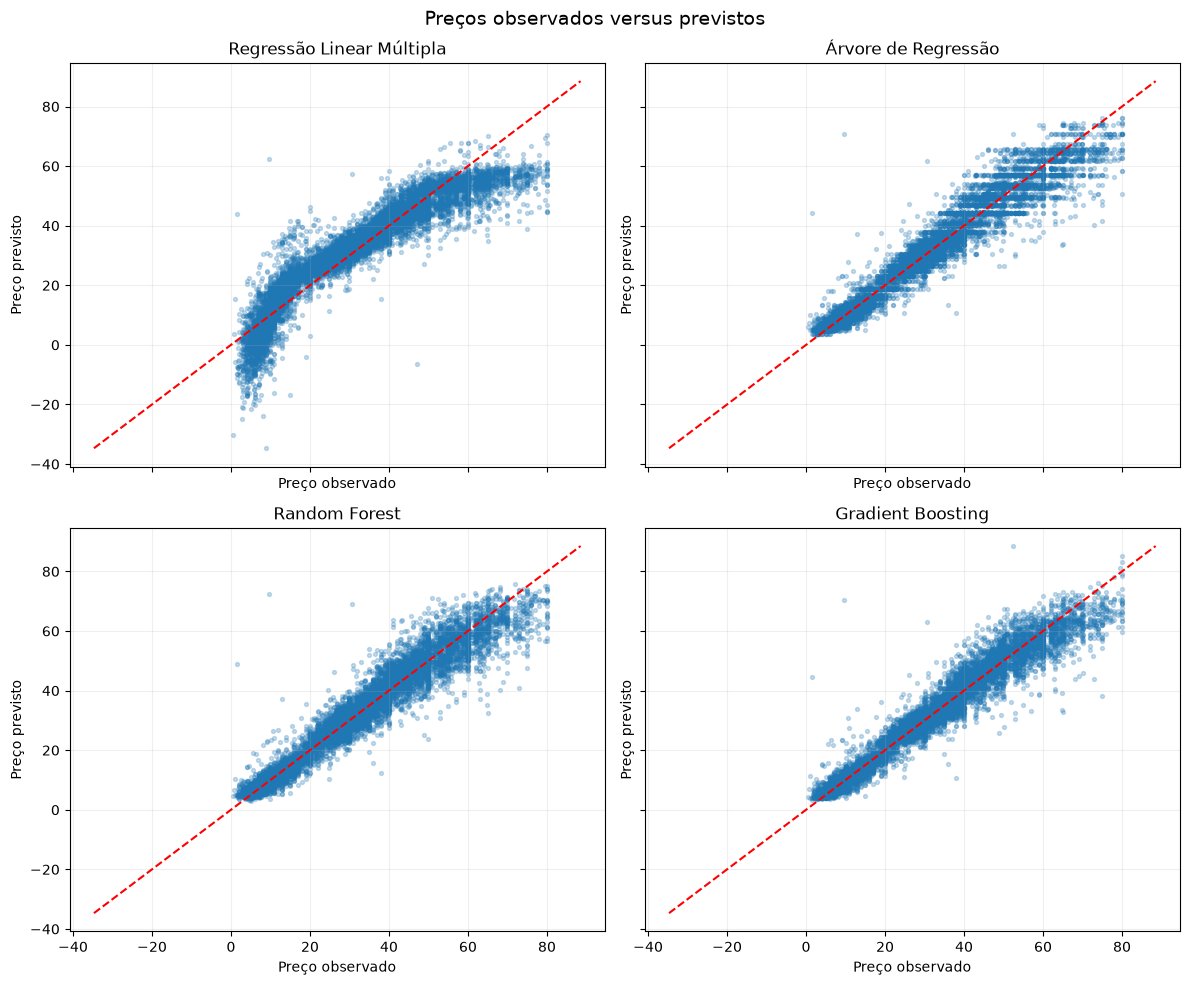

In [10]:
previsoes = {
    "Regressão Linear Múltipla": pred_linear,
    "Árvore de Regressão": pred_arvore,
    "Random Forest": pred_rf,
    "Gradient Boosting": pred_boost,
}

limite_inferior = min(y_teste.min(), *(p.min() for p in previsoes.values()))
limite_superior = max(y_teste.max(), *(p.max() for p in previsoes.values()))

fig, eixos = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

for eixo, (nome, previsto) in zip(eixos.flat, previsoes.items()):
    eixo.scatter(y_teste, previsto, s=8, alpha=0.25)
    eixo.plot(
        [limite_inferior, limite_superior],
        [limite_inferior, limite_superior],
        linestyle="--",
        color="red",
    )
    eixo.set_title(nome)
    eixo.set_xlabel("Preço observado")
    eixo.set_ylabel("Preço previsto")
    eixo.grid(alpha=0.2)

fig.suptitle("Preços observados versus previstos", fontsize=14)
fig.tight_layout()

Path("resultados").mkdir(exist_ok=True)
fig.savefig(
    Path("resultados") / "observado_previsto_automoveis_python.png",
    dpi=300,
)
plt.show()

## 10. Discussão

A referência pela média estabelece o desempenho mínimo. A regressão linear reduz fortemente o erro, mostrando que as características contêm informação relevante, mas os métodos baseados em árvores capturam relações não lineares e interações.

Nesta divisão, o Gradient Boosting apresenta o menor RMSE. A árvore individual e a Random Forest têm desempenho próximo, enquanto a regressão linear fica atrás dos métodos baseados em árvores. A recomendação deve permanecer limitada a esta base, divisão e conjunto de configurações.